<a href="https://colab.research.google.com/github/naylaviona/Studi-Kasus-Informatics-Practitioner-Lecture-Series/blob/main/StudiKasus1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#STUDI KASUS 1: MAKE SENSE OF DATA WITH ANALYSIS AND AI
#PEMATERI: ANDRIA ARISAL

## Judul Studi Kasus: Prediksi Risiko Keterlambatan Pembayaran (Late Payment) Transaksi B2B Menggunakan Algoritma Klasifikasi (Studi Kasus Adaptasi PT Maju Bersama)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# 1. DATA GENERATION (Membuat Dataset Sintetis PT Maju Bersama)
np.random.seed(42)
n_samples = 1000

In [ ]:
# Simulasi fitur-fitur bisnis
data = {
    'customer_loyalty_years': np.random.randint(1, 10, n_samples),
    'invoice_amount': np.random.randint(5000000, 100000000, n_samples),
    'payment_term_days': np.random.choice([14, 30, 60], n_samples),
    'historical_late_ratio': np.random.uniform(0.0, 0.5, n_samples),
    'discount_given': np.random.uniform(0.0, 0.2, n_samples)
}
df = pd.DataFrame(data)

In [ ]:
# Simulasi Target (is_late)
# Pelanggan dengan tagihan besar, rasio telat historis tinggi, dan diskon anomali lebih rentan telat bayar
prob_late = (df['historical_late_ratio'] * 0.6) + (df['invoice_amount'] / 100000000 * 0.2) + (df['discount_given'] * 0.2)
df['is_late'] = np.where(prob_late > 0.35, 1, 0) # 1 = Late, 0 = Not Late

In [ ]:
# Tampilkan sekilas data
print("Data Overview:")
display(df.head())

Data Overview:


,customer_loyalty_years,invoice_amount,payment_term_days,historical_late_ratio,discount_given,is_late
0,7,57934615,60,0.019883,0.164120,0
1,4,41992982,30,0.302036,0.080914,0
2,8,72185082,30,0.453690,0.096869,1
3,5,28656190,30,0.119428,0.002674,0
4,7,89656124,60,0.234821,0.081948,0


In [ ]:
# 2. DATA PREPARATION (Preprocessing)
# Memisahkan Fitur (X) dan Target (y)
X = df.drop('is_late', axis=1)
y = df['is_late']

In [ ]:
# Membagi data menjadi Train (80%) dan Test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
# Standarisasi Data (Penting agar model tidak bias pada angka nominal besar seperti invoice_amount)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# 3. MODELING (Melatih Model Machine Learning)
# Menggunakan Random Forest
# class_weight='balanced' ditambahkan untuk mengatasi data yang tidak seimbang (Imbalanced Data)
rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf_model.fit(X_train_scaled, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [ ]:
# Melakukan Prediksi
y_pred = rf_model.predict(X_test_scaled)

In [ ]:
# 4. EVALUATION (Evaluasi Model)
# ---------------------------------------------------------
print("\n--- HASIL EVALUASI MODEL ---")
print("Accuracy Score:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


--- HASIL EVALUASI MODEL ---
Accuracy Score: 0.96

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.98      0.97       145
           1       0.94      0.91      0.93        55

    accuracy                           0.96       200
   macro avg       0.95      0.94      0.95       200
weighted avg       0.96      0.96      0.96       200



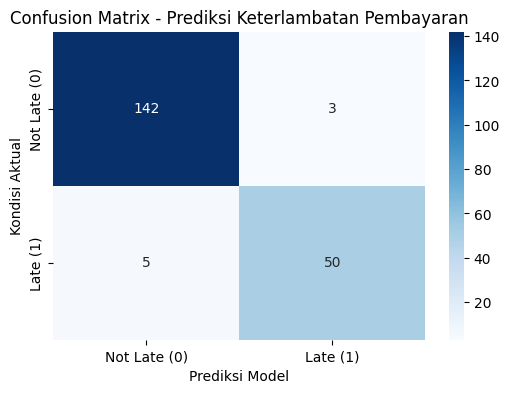

In [ ]:
# Visualisasi Confusion Matrix
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Late (0)', 'Late (1)'],
            yticklabels=['Not Late (0)', 'Late (1)'])
plt.title('Confusion Matrix - Prediksi Keterlambatan Pembayaran')
plt.xlabel('Prediksi Model')
plt.ylabel('Kondisi Aktual')
plt.show()

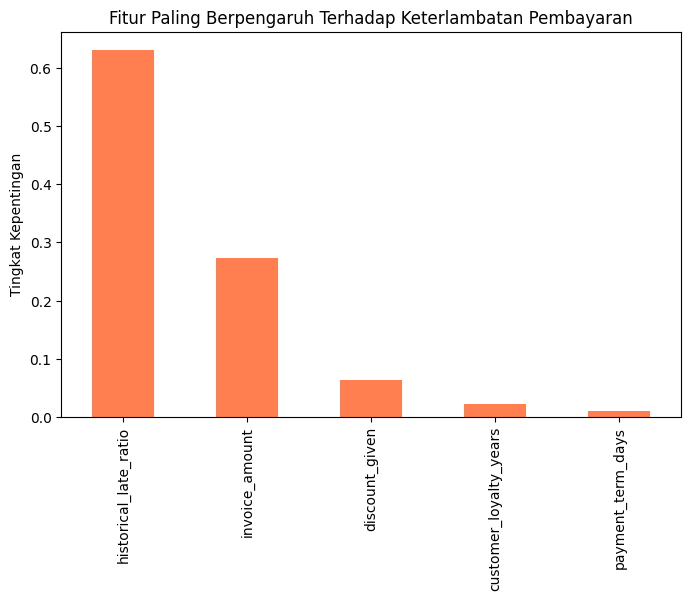

In [ ]:
# Visualisasi Feature Importance (Mencari tahu penyebab keterlambatan)
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8,5))
feature_importances.plot(kind='bar', color='coral')
plt.title('Fitur Paling Berpengaruh Terhadap Keterlambatan Pembayaran')
plt.ylabel('Tingkat Kepentingan')
plt.show()